# Analysis Notebook 1 EUROSTAT
### Kevin Derderian 
### 11/15/2026

In [4]:
import requests
import time
import json
import pandas as pd
import matplotlib.pyplot as plt
from urllib.robotparser import RobotFileParser

HEADERS = {
    "User-Agent": "WebDataScience/1.0 (INFO 4617; kevin.derderian@colorado.edu)"
}

URL = "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/env_wasmun"

In [44]:
# Setup: libraries and file paths
import json
import os

import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "eurostat_waste_2005_2023.csv"
RAW_PATH = "eurostat_env_wasmun_raw.json"        


FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)  

for path in [CSV_PATH, RAW_PATH]:
    print(path, os.path.exists(path))

eurostat_waste_2005_2023.csv True
eurostat_env_wasmun_raw.json True


In [48]:
df = pd.read_csv(CSV_PATH)

print(df.shape)     
print(df.dtypes)
df.head()

(3591, 4)
geo               object
wst_oper          object
year               int64
kg_per_person    float64
dtype: object


,geo,wst_oper,year,kg_per_person
0,AT,GEN,2005,575.0
1,AT,GEN,2006,597.0
2,AT,GEN,2007,597.0
3,AT,GEN,2008,600.0
4,AT,GEN,2009,590.0


### Key reminders

    "GEN",        # Waste generated (the total each share is divided by)
    "DSP_L_OTH",  # Landfill and other disposal
    "RCV_E",      # Energy recovery (R1): this is waste-to-energy
    "DSP_I",      # Incineration WITHOUT energy recovery (D10)
    "RCY",        # Recycling, total
    "RCY_M",      # material
    "RCY_C_D",    # composting and digestion
    UNIT = "KG_HAB"   # Kilograms per capita

## Does my collected data table check off what was in my proposal? 
### 27 Countries 
### 7 Operations 
### 19 years of collected data
### 7 x 19 = 133 data entries per EU nation

In [57]:
print("Countries:", df["geo"].nunique())            
print("Operations:", sorted(df["wst_oper"].unique())) 
print("Years:", df["year"].min(), "to", df["year"].max(), "-", df["year"].nunique(), "years")  

print(df.groupby("geo").size().unique())             

Countries: 27
Operations: ['DSP_I', 'DSP_L_OTH', 'GEN', 'RCV_E', 'RCY', 'RCY_C_D', 'RCY_M']
Years: 2005 to 2023 - 19 years
[133]


## Checking for missing values

In [64]:
missing = df[df["kg_per_person"].isna()]
print("Missing values:", len(missing), "of", len(df),
      f"({len(missing) / len(df):.1%})")              

print(missing.groupby("geo").size().sort_values(ascending=False))

missing.groupby(["geo", "wst_oper"])["year"].apply(list)

Missing values: 38 of 3591 (1.1%)
geo
IE    14
HR     9
DK     7
EL     3
NL     3
LV     2
dtype: int64


geo  wst_oper 
DK   DSP_I                    [2010]
     DSP_L_OTH                [2010]
     GEN                      [2010]
     RCV_E                    [2010]
     RCY                      [2010]
     RCY_C_D                  [2010]
     RCY_M                    [2010]
EL   DSP_I        [2013, 2014, 2015]
HR   DSP_I                    [2005]
     DSP_L_OTH                [2005]
     RCV_E                    [2005]
     RCY                [2005, 2006]
     RCY_C_D            [2005, 2006]
     RCY_M              [2005, 2006]
IE   DSP_I              [2013, 2015]
     DSP_L_OTH          [2013, 2015]
     GEN                [2013, 2015]
     RCV_E              [2013, 2015]
     RCY                [2013, 2015]
     RCY_C_D            [2013, 2015]
     RCY_M              [2013, 2015]
LV   DSP_I                    [2023]
     DSP_L_OTH                [2023]
NL   RCV_E        [2005, 2006, 2007]
Name: year, dtype: object

### 38/3591 missing

In [67]:
# Load the raw API responses saved by the collection notebook
with open(RAW_PATH) as f:
    raw = json.load(f)
print(len(raw), "responses")   # expected: 189

flag_labels = {}   # what each flag letter means, according to Eurostat
flag_rows = []     # one row per flagged value

for key, data in raw.items():
    geo, op = key.split("_", 1)

    # Eurostat's own definitions of the flags (not every response has them)
    flag_labels.update(data.get("extension", {}).get("status", {}).get("label", {}))

    # Map each position back to its year, e.g. {"0": 1995, "1": 1996, ...}
    time_index = data["dimension"]["time"]["category"]["index"]
    pos_to_year = {str(pos): int(year) for year, pos in time_index.items()}

    for pos, flag in data.get("status", {}).items():
        flag_rows.append({
            "geo": geo,
            "wst_oper": op,
            "year": pos_to_year[pos],
            "flag": flag
        })

flags = pd.DataFrame(flag_rows)
flags = flags[(flags["year"] >= 2005) & (flags["year"] <= 2023)]   # same window as the CSV

print(flag_labels)
print(flags["flag"].value_counts())

189 responses
{'b': 'break in time series', 'e': 'estimated', 'i': 'value imputed by Eurostat or other receiving agencies', 'p': 'provisional', 'be': 'break in time series, estimated'}
flag
e     262
b      95
i      56
p      21
be     15
Name: count, dtype: int64


In [103]:
wide = df.pivot(index=["geo", "year"], columns="wst_oper", values="kg_per_person").reset_index()

print(wide.shape)   
wide.head()

(513, 9)


wst_oper,geo,year,DSP_I,DSP_L_OTH,GEN,RCV_E,RCY,RCY_C_D,RCY_M
0,AT,2005,0.0,65.0,575.0,159.0,335.0,192.0,143.0
1,AT,2006,0.0,59.0,597.0,173.0,353.0,201.0,152.0
2,AT,2007,0.0,51.0,597.0,175.0,359.0,200.0,159.0
3,AT,2008,0.0,45.0,600.0,163.0,380.0,202.0,177.0
4,AT,2009,0.0,36.0,590.0,173.0,365.0,186.0,179.0


In [99]:
wide["landfill_pct"]        = wide["DSP_L_OTH"] / wide["GEN"] * 100
wide["wte_pct"]             = wide["RCV_E"]     / wide["GEN"] * 100
wide["incin_no_energy_pct"] = wide["DSP_I"]     / wide["GEN"] * 100
wide["recycling_pct"]       = wide["RCY"]       / wide["GEN"] * 100

wide[wide["geo"] == "DK"][["geo", "year", "landfill_pct", "wte_pct", "recycling_pct"]] \
    .query("year in [2005, 2023]").round(1)

wst_oper,geo,year,landfill_pct,wte_pct,recycling_pct
114,DK,2005,5.2,53.8,41.0
132,DK,2023,1.8,51.0,46.6


In [97]:
wide["accounted_pct"] = wide[["landfill_pct", "wte_pct", "incin_no_energy_pct", "recycling_pct"]].sum(axis=1, min_count=4)
print(wide["accounted_pct"].describe().round(1))

count    501.0
mean      95.6
std        7.0
min       59.7
25%       93.0
50%       98.9
75%      100.0
max      116.3
Name: accounted_pct, dtype: float64


In [95]:
wide.groupby("year")[["landfill_pct", "wte_pct", "recycling_pct"]].median().round(1).loc[[2005, 2023]]

wst_oper,landfill_pct,wte_pct,recycling_pct
year,,,
2005,62.8,0.9,18.6
2023,18.6,18.4,43.3


In [113]:
# All burning of waste, whether or not it is officially counted as energy recovery
wide["incineration_total_pct"] = wide["wte_pct"] + wide["incin_no_energy_pct"]

In [111]:
# Step 5 + 6a in one cell: build the wide table and add all share columns
wide = df.pivot(index=["geo", "year"], columns="wst_oper", values="kg_per_person").reset_index()

wide["landfill_pct"]           = wide["DSP_L_OTH"] / wide["GEN"] * 100
wide["wte_pct"]                = wide["RCV_E"]     / wide["GEN"] * 100
wide["incin_no_energy_pct"]    = wide["DSP_I"]     / wide["GEN"] * 100
wide["recycling_pct"]          = wide["RCY"]       / wide["GEN"] * 100
wide["incineration_total_pct"] = wide["wte_pct"] + wide["incin_no_energy_pct"]
wide["accounted_pct"] = wide[["landfill_pct", "wte_pct", "incin_no_energy_pct", "recycling_pct"]].sum(axis=1, min_count=4)

print(wide.shape)               # expected: (513, 15)
print(wide.columns.tolist())

(513, 15)
['geo', 'year', 'DSP_I', 'DSP_L_OTH', 'GEN', 'RCV_E', 'RCY', 'RCY_C_D', 'RCY_M', 'landfill_pct', 'wte_pct', 'incin_no_energy_pct', 'recycling_pct', 'incineration_total_pct', 'accounted_pct']


In [115]:
key_cols = ["landfill_pct", "wte_pct", "incineration_total_pct", "recycling_pct"]

# Keep only country-years where all four shares exist
complete = wide.dropna(subset=key_cols)

# Each country's earliest and latest complete year
first = complete.loc[complete.groupby("geo")["year"].idxmin()].set_index("geo")
last  = complete.loc[complete.groupby("geo")["year"].idxmax()].set_index("geo")

# Most countries should be 2005 to 2023
print(pd.DataFrame({"start_year": first["year"], "end_year": last["year"]}).value_counts())

start_year  end_year
2005        2023        24
            2022         1
2007        2023         1
2008        2023         1
Name: count, dtype: int64


In [117]:
changes = pd.DataFrame({"start_year": first["year"], "end_year": last["year"]})

for col in key_cols:
    name = col.replace("_pct", "")
    changes[f"{name}_start"]  = first[col]
    changes[f"{name}_end"]    = last[col]
    changes[f"{name}_change"] = last[col] - first[col]   # in percentage points

changes = changes.round(1).sort_values("wte_change", ascending=False)
changes[["start_year", "end_year", "landfill_change", "wte_change",
         "incineration_total_change", "recycling_change"]]

,start_year,end_year,landfill_change,wte_change,incineration_total_change,recycling_change
geo,,,,,,
FI,2005,2023,-58.6,46.7,45.5,11.2
EE,2005,2023,-62.5,42.6,42.6,15.4
IE,2005,2023,-45.9,42.5,42.5,10.8
LT,2005,2023,-83.4,40.4,40.4,47.5
NL,2008,2023,0.0,30.7,-9.4,9.6
DE,2005,2023,-7.5,28.3,-0.1,7.8
PL,2005,2023,-40.6,19.9,20.4,21.9
SI,2005,2023,-57.1,11.2,13.1,41.1
BE,2005,2023,-11.5,9.0,6.7,0.2


In [119]:
# How many breaks in series fall in each country's key series between its start and end year?
key_ops = ["DSP_L_OTH", "RCV_E", "DSP_I", "RCY"]
b = df[df["flag"].str.contains("b") & df["wst_oper"].isin(key_ops)]
b = b.merge(changes[["start_year", "end_year"]], left_on="geo", right_index=True)
b = b[(b["year"] > b["start_year"]) & (b["year"] <= b["end_year"])]

changes["breaks_in_period"] = b.groupby("geo").size()
changes["breaks_in_period"] = changes["breaks_in_period"].fillna(0).astype(int)

changes.to_csv(os.path.join(os.path.dirname(CSV_PATH), "country_changes.csv"))
print(changes.shape)   # expected: (27, 15)

(27, 15)


In [121]:
change_cols = ["landfill_change", "wte_change", "incineration_total_change", "recycling_change"]

# Pearson correlation: does a bigger change in one go with a bigger change in another?
corr = changes[change_cols].corr().round(2)
corr

,landfill_change,wte_change,incineration_total_change,recycling_change
landfill_change,1.00,-0.57,-0.74,-0.62
wte_change,-0.57,1.00,0.81,0.03
incineration_total_change,-0.74,0.81,1.00,0.09
recycling_change,-0.62,0.03,0.09,1.00


In [123]:
# Spearman uses ranks instead of values, so one extreme country (e.g. Lithuania) can't drive the result
changes[change_cols].corr(method="spearman").round(2)

,landfill_change,wte_change,incineration_total_change,recycling_change
landfill_change,1.00,-0.41,-0.56,-0.60
wte_change,-0.41,1.00,0.67,-0.04
incineration_total_change,-0.56,0.67,1.00,-0.02
recycling_change,-0.60,-0.04,-0.02,1.00


In [125]:
# Group countries by how much waste they burned at the start (total incineration, so relabeling doesn't matter)
changes["start_group"] = changes["incineration_total_start"].apply(
    lambda x: "High incineration at start (30%+)" if x >= 30 else "Low incineration at start (<30%)"
)

group_summary = changes.groupby("start_group").agg(
    countries=("start_year", "size"),
    recycling_start=("recycling_start", "mean"),
    recycling_end=("recycling_end", "mean"),
    recycling_change=("recycling_change", "mean"),
    landfill_change=("landfill_change", "mean"),
    incineration_change=("incineration_total_change", "mean"),
).round(1)

print(changes[changes["start_group"].str.startswith("High")].index.tolist())
group_summary

['NL', 'DE', 'BE', 'SE', 'LU', 'FR', 'DK']


,countries,recycling_start,recycling_end,recycling_change,landfill_change,incineration_change
start_group,,,,,,
High incineration at start (30%+),7,46.2,52.2,6.0,-8.2,0.5
Low incineration at start (<30%),20,15.3,37.1,21.8,-33.1,12.0


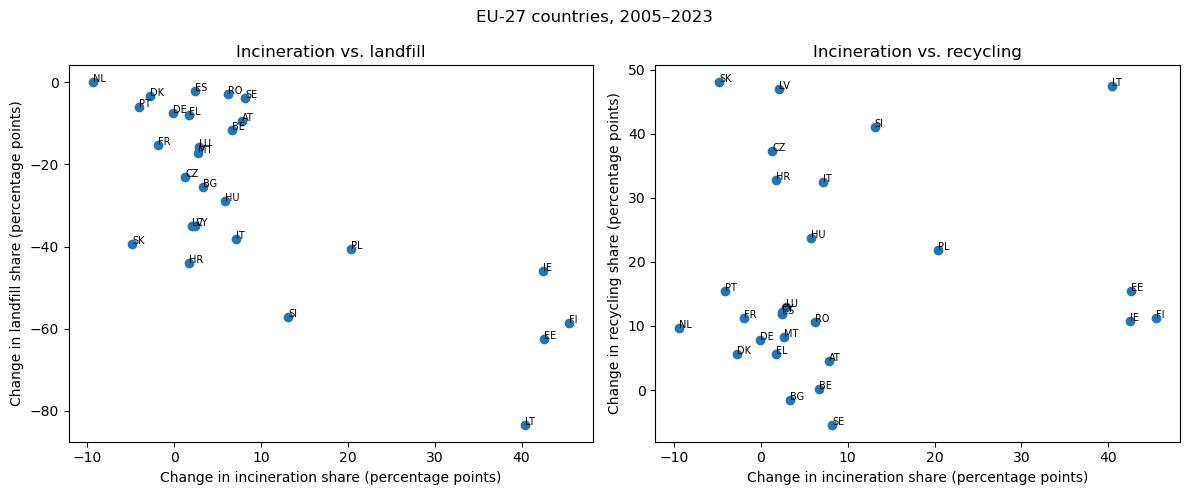

In [129]:
# Figure 1: incineration change vs. landfill and recycling change, one dot per country
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col, label in zip(axes, ["landfill_change", "recycling_change"], ["landfill", "recycling"]):
    ax.scatter(changes["incineration_total_change"], changes[col])
    for geo in changes.index:
        ax.annotate(geo, (changes.loc[geo, "incineration_total_change"], changes.loc[geo, col]), fontsize=7)
    ax.set_title(f"Incineration vs. {label}")
    ax.set_xlabel("Change in incineration share (percentage points)")
    ax.set_ylabel(f"Change in {label} share (percentage points)")

fig.suptitle("EU-27 countries, 2005–2023")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_incineration_vs_landfill_recycling.png"), dpi=150)
plt.show()

## Preliminary findings

1. **Incineration and landfilling:** Countries that increased incineration cut landfilling the most
   (r = −0.74 across 27 countries). Finland, Estonia, Ireland and Lithuania added 40+ points of
   incineration and cut landfilling by 46–83 points.
2. **Incineration and recycling:** Incineration growth had no clear relationship with recycling change
   (r = 0.09; Spearman −0.03). Recycling rose in 25 of 27 countries; it fell only in Sweden (−5.4)
   and Bulgaria (−1.5).
3. **High starters:** The 7 countries already burning 30%+ of their waste in 2005 (BE, DE, DK, FR, LU,
   NL, SE) raised recycling by only +6.0 points, compared with +21.8 for the other 20. But they started
   with much higher recycling (46% vs. 15%), so they had less room to grow.
4. **Relabeling:** Most of Germany's and the Netherlands' apparent WTE growth is existing incinerators
   being reclassified from D10 to R1, so total incineration is used as the main measure.

 27 countries is a small sample, correlations do not show cause, and 19 countries
have at least one break in series in the key data.